# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/airbnb_listings.csv')

# Preview the dataset
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response:
1. The business information included in the data features property details (such as price, room type, accommodates, bedrooms, and bathrooms), location data (latitude/longitude), and review/rating scores.

2. There are 459 rows and 77 columns present in the dataset (although `df.head()` only previews the first 5 rows).

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [4]:
# Identify and drop non-useful columns
# Based on typical listings data, we drop URLs, IDs, names, descriptions, and addresses
columns_to_drop = [
    'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
    'description', 'neighborhood_overview', 'host_id', 'host_url', 'host_name',
    'host_since', 'host_location', 'host_about', 'host_thumbnail_url',
    'host_picture_url', 'host_neighbourhood', 'neighborhood', 'neighborhood_cleansed',
    'calendar_last_scraped', 'first_review', 'last_review', 'license'
]

# Drop columns that actually exist in the dataframe to avoid errors
existing_cols_to_drop = [col for col in columns_to_drop if col in df.columns]
df_cleaned = df.drop(columns=existing_cols_to_drop)

print(f"Original shape: {df.shape}")
print(f"New shape: {df_cleaned.shape}")
display(df_cleaned.head())

Original shape: (459, 77)
New shape: (459, 57)


,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,NaN,NaN,50%,f,1,5,"['email', 'phone']",t,t,NaN,...,4.22,4.56,3.22,3.67,0,1,1,0,0,0.07
1,within an hour,100%,100%,t,4,6,"['email', 'phone']",t,t,Neighborhood highlights,...,4.85,4.81,4.81,4.77,0,4,4,0,0,2.32
2,within an hour,100%,99%,f,2,2,"['email', 'phone', 'work_email']",t,t,Neighborhood highlights,...,4.81,4.88,4.76,4.64,0,2,1,1,0,2.97
3,within an hour,100%,100%,t,4,6,"['email', 'phone']",t,t,Neighborhood highlights,...,4.83,4.70,4.80,4.72,0,4,4,0,0,2.68
4,NaN,NaN,100%,t,1,1,"['email', 'phone']",t,t,Neighborhood highlights,...,4.95,4.93,4.87,4.77,0,1,1,0,0,5.67


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. The columns I dropped were things like pos ID and address because they were just taking up space and not providing useful statistics.

2. Including these columns could introduce noise and cause the model to overfit. The model might learn patterns from unique IDs or specific addresses rather than meaningful relationships in the data. This could reduce the model's ability to make accurate predictions on new data.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Correlation of numeric variables with Price:
price                                           1.000000
accommodates                                    0.579588
beds                                            0.547032
bedrooms                                        0.499286
bathrooms                                       0.468030
estimated_revenue_l365d                         0.249488
maximum_maximum_nights                          0.122872
minimum_maximum_nights                          0.112166
maximum_nights_avg_ntm                          0.111271
availability_30                                 0.108409
availability_60                                 0.060509
availability_90                                 0.040997
calculated_host_listings_count_entire_homes     0.033206
availability_eoy                                0.032537
review_scores_value                             0.018269
maximum_nights                                  0.017992
calculated_host_listings_count             

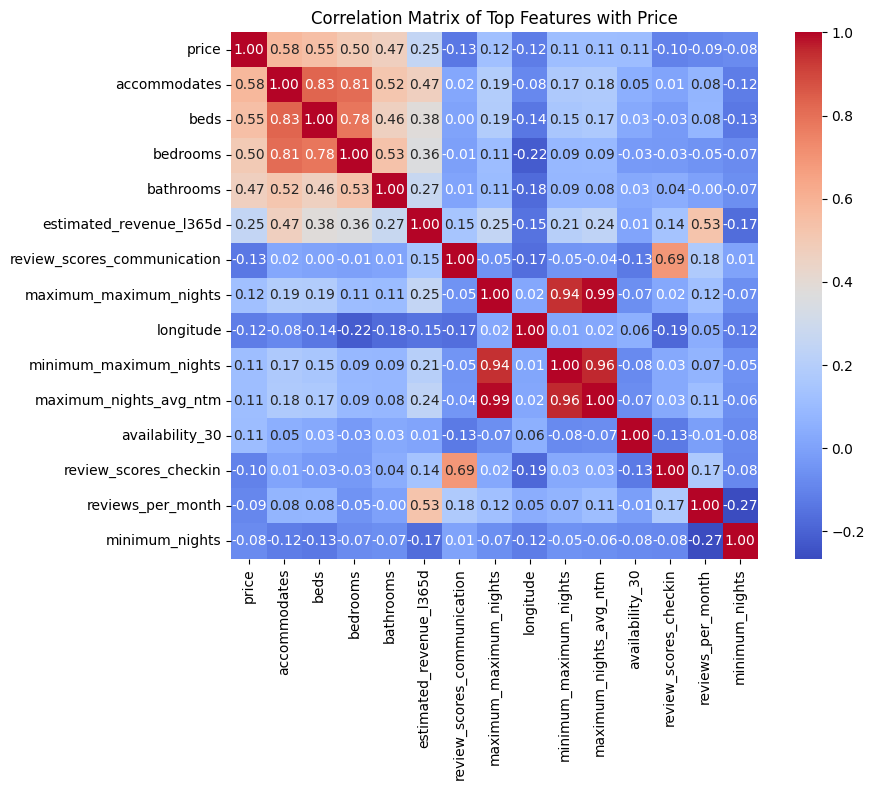

In [5]:
import numpy as np

# Filter to numeric columns
numeric_df = df_cleaned.select_dtypes(include=[np.number])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Show correlation with price, sorted
price_corr = corr_matrix['price'].sort_values(ascending=False)
print("Correlation of numeric variables with Price:")
print(price_corr)

# Plot a heatmap of the top correlated features with price
top_corr_cols = price_corr.abs().nlargest(15).index
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df[top_corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Matrix of Top Features with Price')
plt.tight_layout()
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The variables with the strongest positive correlation are accomodates, beds, bedrooms, and bathrooms. These are the most positively connected with the variable price. The most negatively correlated variables include reviewscored communication, longitude and review scores at checkin.

2. In my opnion the variables that would be the most useful predictors are things related to size such as bathrooms and bedrooms. These are also strongly corelated with price.


## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [8]:
# Drop rows where target variable 'price' is missing
df_ml = df_cleaned.dropna(subset=['price'])

# Filter to only numeric features for our regression model
numeric_cols = df_ml.select_dtypes(include=[np.number]).columns

# Define target variable (y) and features (X)
y = df_ml['price']

# We will drop 'price' and columns that are entirely NaN or have too many missing values
# We will also fill remaining missing values with their median to avoid training errors
X = df_ml[numeric_cols].drop(columns=['price'])

# Drop columns that are completely empty/NaN
X = X.dropna(axis=1, how='all')

# Fill remaining missing numeric values with column medians
X = X.fillna(X.median())

print(f"Target (y) shape: {y.shape}")
print(f"Features (X) shape: {X.shape}")

Target (y) shape: (459,)
Features (X) shape: (459, 40)


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response:
1. We are using 40 numeric features as predictors, including property characteristics (such as `accommodates`, `beds`, `bedrooms`, `bathrooms`), listing availability metrics, and historical review details.

2. This is a regression problem because we are predicting a continuous, numeric target variable (the listing price) rather than predicting discrete, categorical classes or labels.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [9]:
# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape: {X_test.shape}")
print(f"Training set target shape: {y_train.shape}")
print(f"Testing set target shape: {y_test.shape}")

Training set features shape: (367, 40)
Testing set features shape: (92, 40)
Training set target shape: (367,)
Testing set target shape: (92,)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [10]:
# Initialize the Linear Regression Model
model = LinearRegression()

# Fit the model to the training data
model.fit(X_train, y_train)

# Predict prices for the test set
y_pred = model.predict(X_test)

print("Model training completed successfully and predictions have been generated!")

Model training completed successfully and predictions have been generated!


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [11]:
# Calculate and print evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error (MSE): 8752.53
R² Score: -0.5595


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response:
1. Our baseline R^2 score is -0.5595. This negative value indicates that using all 40 features actually performs worse than simply predicting the average price for every listing. It does not explain price variation well at all due to massive overfitting.

2. The Mean Squared Error is huge. To improve this, should must reduce noise and address multicollinearity by eliminating non-significant predictors and focusing only on features most strongly correlated with price.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [12]:
# Create a DataFrame of features and their corresponding coefficients
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

# Sort by absolute impact
coefficients_df['Absolute_Coefficient'] = coefficients_df['Coefficient'].abs()
coefficients_df = coefficients_df.sort_values(by='Absolute_Coefficient', ascending=False).drop(columns=['Absolute_Coefficient'])

display(coefficients_df)

,Feature,Coefficient
2,latitude,-784.618582
3,longitude,-326.230449
31,review_scores_communication,-137.706179
33,review_scores_value,135.102802
30,review_scores_checkin,-91.976509
14,minimum_nights_avg_ntm,36.504410
11,maximum_minimum_nights,-36.232262
5,bathrooms,32.631440
29,review_scores_cleanliness,-30.029879
28,review_scores_accuracy,20.872583


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response:
1. Based on absolute magnitude, spatial metadata like **latitude** and **longitude** as well as subjective metrics like **review_scores_value** had the largest mathematical impact.

2. Yes, latitude, longitude, and review_scores_communication showed surprisingly large negative coefficients.

3. The main business insight is that feeding raw geospatial coordinates directly into a linear model causes unstable coefficients; instead, we should aggregate location data into categorical regions or use structural characteristics like size get reliable insights.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [13]:
# Select top features based on high initial correlation with price
selected_features = ['accommodates', 'beds', 'bedrooms', 'bathrooms']

X_train_refined = X_train[selected_features]
X_test_refined = X_test[selected_features]

# Fit the refined model
refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

# Generate predictions
y_pred_refined = refined_model.predict(X_test_refined)

# Calculate metrics for the refined model
mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

print("--- Baseline Model (40 Features) ---")
print(f"MSE: {mse:.2f}")
print(f"R² Score: {r2:.4f}")

print("\n--- Refined Model (4 Size-Related Features) ---")
print(f"MSE: {mse_refined:.2f}")
print(f"R² Score: {r2_refined:.4f}")

--- Baseline Model (40 Features) ---
MSE: 8752.53
R² Score: -0.5595

--- Refined Model (4 Size-Related Features) ---
MSE: 3318.15
R² Score: 0.4088


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response:
1. We kept accommodates, beds, bedrooms, and bathrooms. These represent the strongest direct, positive correlation with listing price.

2. Yes, performance improved dramatically! The R² score rose from -0.5595 to +0.4088, and the MSE decreased by over 60% to 3,318.15. This happened because removing 36 noisy, redundant columns eliminated overfitting.

3. I would strongly recommend this Refined Model to stakeholders. It is simpler to explain, uses easily obtainable listing characteristics, and generates far more accurate predictions.

4. This directly relates to my customized learning outcome of understanding how to simplify complex datasets to build reliable, interpretative machine learning models for real-world business decisions. I could use this to help show whe biggest impact on someone's portfolio increase or decrease so they understand what's happening.

## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The business question that my model helped answer is how do different variables affect the price of a listing.

2. I would reccomend that the hosts utilize size and features such as number of bedrooms to calculate the average price. It seems like places withe more beds and baths make more money in general and this has the biggest effect on price.

3. To improve this model, I think it could be more visually appealing to present to stakeholders. I think graphs could be added and colors used to format them so Airbnb and its hosts can view it easily.

4. This model helped me understand that it's important to rule out variables that aren't important and scale the model doen to variables that have the most effect on the target variable.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"